# 02 · Analyse exploratoire (EDA) : activité du terminal SmartPort

**Question métier.** Comment comprendre les volumes, la nature des opérations et les pics d'activité pour planifier les ressources ?

**Données.** Tables `mart_kpi_*` et CORE produites par `01_ETL_Pipeline.ipynb` (à exécuter en premier). Le CSV brut ne sert qu'à l'aperçu initial.

**Plan.** Aperçu → événements par jour → heure et semaine → zones → navires et services → clients → poids → FCL / MTY → conclusions.

**Méthode.** Pour ne pas inventer de tendances, chaque écart apparent est testé :
| Outil | Question |
|---|---|
| Indice de dispersion (variance / moyenne) | ≈ 1 : les événements arrivent comme au hasard |
| Test du χ² d'uniformité | les catégories ont-elles des effectifs compatibles avec l'égalité ? |
| ANOVA | les moyennes de plusieurs groupes diffèrent-elles ? |
| Mann-Whitney | deux distributions diffèrent-elles ? |

Un écart est dit significatif si **p < 0,05**. Plusieurs tests sont réalisés : une valeur isolée proche de ce seuil peut apparaître par hasard. Une valeur p élevée ne prouve pas l'égalité : elle indique qu'on ne peut pas conclure à une différence.

## 0. Préparation

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "03_data" / "raw").is_dir()), None)
assert ROOT is not None, "Lancez le notebook depuis le dossier du projet."
DB_PATH = ROOT / "03_data" / "warehouse" / "smartport_complet.db"
CSV_PATH = ROOT / "03_data" / "raw" / "container_events.csv"
FIG_DIR = ROOT / "06_results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert DB_PATH.exists(), "Exécutez d'abord 01_ETL_Pipeline.ipynb."
con = sqlite3.connect(DB_PATH)

def q(sql):
    """Résultat d'une requête sur l'entrepôt, sous forme de tableau."""
    return pd.read_sql(sql, con)

In [2]:
# Style commun et export de chaque figure en PNG dans 06_results/figures/
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
                     "axes.titlesize": 11.5, "axes.titleweight": "bold"})
BLEU, ORANGE, GRIS, ROUGE, VERT = "#2E6FBA", "#E08A1E", "#8A8F98", "#C8423B", "#2F9E6E"

def sauver(nom):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nom}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Aperçu du jeu de données principal
Dimensions, premières lignes et statistiques descriptives de `container_events.csv`.

In [3]:
df = pd.read_csv(CSV_PATH)
print(df.shape)                                   # (lignes, colonnes)
display(df.head())
display(df.describe(include="all").transpose())

(9000, 9)


,event_id,container_id,customer_id,vessel_id,event_type,event_ts,yard_area,freight_status,gross_weight_kg
0,1,CONT0003316,C050,V030,MOVE,2026-03-25 01:47:32,Y08B,FCL,8822.5
1,2,CONT0000650,C079,V074,SEAL,2026-03-19 23:42:20,Y02,FCL,24343.6
2,3,CONT0000269,C013,V006,SEAL,2026-03-20 15:15:26,Y04,FCL,20569.2
3,4,CONT0001082,C051,V038,DELIVER,2026-06-18 09:43:51,Y08B,FCL,30817.3
4,5,CONT0002622,C027,V095,DISCHARGE,2026-06-26 09:49:04,Y08,MTY,25745.9


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
event_id,9000.0,NaN,NaN,NaN,4500.5,2598.220545,1.0,2250.75,4500.5,6750.25,9000.0
container_id,9000,3242,CONT0002524,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,9000,80,C067,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vessel_id,9000,120,V020,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_type,9000,7,MOVE,2840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event_ts,9000,8998,2026-03-13 06:08:40,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
yard_area,9000,6,Y04,1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freight_status,9000,2,FCL,6824,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gross_weight_kg,9000.0,NaN,NaN,NaN,18595.543267,5505.635162,2000.0,14910.525,18560.65,22357.075,35000.0


In [4]:
# Complétude et unicité : préalable à toute statistique
print("Cellules vides :", int(df.isna().sum().sum()), "| event_id en double :", int(df.event_id.duplicated().sum()))
print("Conteneurs distincts :", df.container_id.nunique())
display(df.gross_weight_kg.describe().round(1))
display(df.event_type.value_counts())

Cellules vides : 0 | event_id en double : 0
Conteneurs distincts : 3242


count     9000.0
mean     18595.5
std       5505.6
min       2000.0
25%      14910.5
50%      18560.6
75%      22357.1
max      35000.0
Name: gross_weight_kg, dtype: float64

event_type
MOVE         2840
DISCHARGE    1413
LOAD         1332
DELIVER      1062
RECEIVE       932
STUFF         714
SEAL          707
Name: count, dtype: int64

**Conclusion.** 9 000 événements et 9 colonnes, aucune cellule vide, aucun doublon d'`event_id`, 3 242 conteneurs distincts. `MOVE` est le type le plus fréquent (2 840).

## 2. KPI 1 : nombre d'événements par jour
### 2.1 Statistiques

In [5]:
# Moyenne, dispersion, seuil des jours chargés et tests sur la période
jour = q("SELECT * FROM mart_kpi_events_per_day ORDER BY full_date")
jour["full_date"] = pd.to_datetime(jour["full_date"])
moy, ecart = jour.nb_evenements.mean(), jour.nb_evenements.std()
seuil = moy + 2 * ecart
pics = jour[jour.nb_evenements > seuil]

print(f"Jours d'activité        : {len(jour)}")
print(f"Moyenne par jour        : {moy:.1f}   écart-type : {ecart:.1f}   min : {jour.nb_evenements.min()}   max : {jour.nb_evenements.max()}")
print(f"Indice de dispersion    : {jour.nb_evenements.var() / moy:.2f}   (≈ 1 = hasard pur)")
print(f"Seuil moyenne + 2 écarts-types : {seuil:.1f}  ->  {len(pics)} jours au-dessus (environ 7 attendus par pur hasard)")
print(f"95 % des jours sont <= {jour.nb_evenements.quantile(.95):.0f} événements, 99 % sont <= {jour.nb_evenements.quantile(.99):.0f}")

# Les jours chargés sont-ils répartis au hasard dans l'année ?
dans = jour.full_date.between("2026-05-01", "2026-07-10")
n_dans = pics.full_date.between("2026-05-01", "2026-07-10").sum()
print(f"\nJours chargés entre le 1er mai et le 10 juillet : {n_dans} sur {len(pics)}  (cette période = {100 * dans.mean():.0f} % du calendrier)")
print(f"Moyenne par jour : {jour[dans].nb_evenements.mean():.1f} dans la période, {jour[~dans].nb_evenements.mean():.1f} en dehors (test t : p = {stats.ttest_ind(jour[dans].nb_evenements, jour[~dans].nb_evenements).pvalue:.3f})")
print("Attention : cette période a été choisie après avoir regardé les données, donc ce p est trop optimiste.")
mensuel = [x.nb_evenements.values for _, x in jour.groupby(jour.full_date.dt.to_period("M"))]
print(f"Comparaison des 10 mois entre eux (ANOVA) : p = {stats.f_oneway(*mensuel).pvalue:.2f}  (pas de mois significativement différent)")

Jours d'activité        : 301
Moyenne par jour        : 29.9   écart-type : 5.6   min : 14   max : 50
Indice de dispersion    : 1.04   (≈ 1 = hasard pur)
Seuil moyenne + 2 écarts-types : 41.0  ->  9 jours au-dessus (environ 7 attendus par pur hasard)
95 % des jours sont <= 39 événements, 99 % sont <= 44

Jours chargés entre le 1er mai et le 10 juillet : 7 sur 9  (cette période = 24 % du calendrier)
Moyenne par jour : 31.1 dans la période, 29.5 en dehors (test t : p = 0.043)
Attention : cette période a été choisie après avoir regardé les données, donc ce p est trop optimiste.
Comparaison des 10 mois entre eux (ANOVA) : p = 0.48  (pas de mois significativement différent)


### 2.2 Graphique

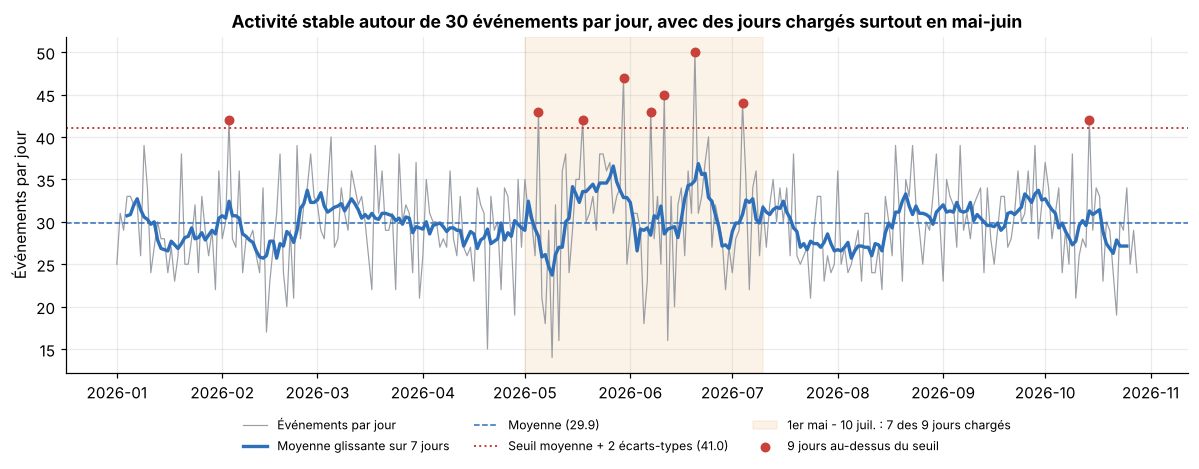

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(jour.full_date, jour.nb_evenements, color=GRIS, lw=0.8, alpha=0.85, label="Événements par jour")
ax.plot(jour.full_date, jour.nb_evenements.rolling(7, center=True).mean(), color=BLEU, lw=2.2, label="Moyenne glissante sur 7 jours")
ax.axhline(moy, color=BLEU, ls="--", lw=1, label=f"Moyenne ({moy:.1f})")
ax.axhline(seuil, color=ROUGE, ls=":", lw=1.3, label=f"Seuil moyenne + 2 écarts-types ({seuil:.1f})")
ax.axvspan(pd.Timestamp("2026-05-01"), pd.Timestamp("2026-07-10"), color=ORANGE, alpha=0.10, label=f"1er mai - 10 juil. : {n_dans} des {len(pics)} jours chargés")
ax.scatter(pics.full_date, pics.nb_evenements, color=ROUGE, zorder=3, s=30, label=f"{len(pics)} jours au-dessus du seuil")
ax.set_title("Activité stable autour de 30 événements par jour, avec des jours chargés surtout en mai-juin")
ax.set_ylabel("Événements par jour")
ax.legend(loc="upper center", ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.1))
sauver("g1_evenements_par_jour")

**Interprétation.**
- Le terminal traite en moyenne **29,9 événements par jour** (de 14 à 50). La moyenne glissante n'indique **aucune tendance** à la hausse ou à la baisse, et les 10 mois ne diffèrent pas significativement entre eux (p = 0,48).
- Jour par jour, la variabilité est celle d'un **tirage aléatoire** : l'indice de dispersion est de 1,04, et 9 jours dépassent le seuil contre environ 7 attendus par hasard. Aucun jour n'est exceptionnel en lui-même.
- **Nuance :** ces 9 jours chargés ne sont pas répartis uniformément. **7 sur 9** tombent entre le 1er mai et le 10 juillet (24 % du calendrier), et la moyenne y est un peu plus élevée (31,1 contre 29,5 ailleurs, soit environ +5 %). C'est un **signe possible de saisonnalité** en mai-juin, mais faible, et la période a été repérée après avoir regardé les données : c'est une **piste à confirmer**, pas une preuve.

**Décision possible.** Dimensionner les équipes sur un flux d'environ 30 événements par jour, avec une marge pour absorber jusqu'à **44 à 50 événements** (le 99e centile est à 44, le maximum observé à 50, le 20/06/2026). Envisager un renfort modéré de mai à début juillet, **à valider avec une deuxième année de données** avant de l'inscrire dans la planification.

## 3. Rythme de la journée et de la semaine

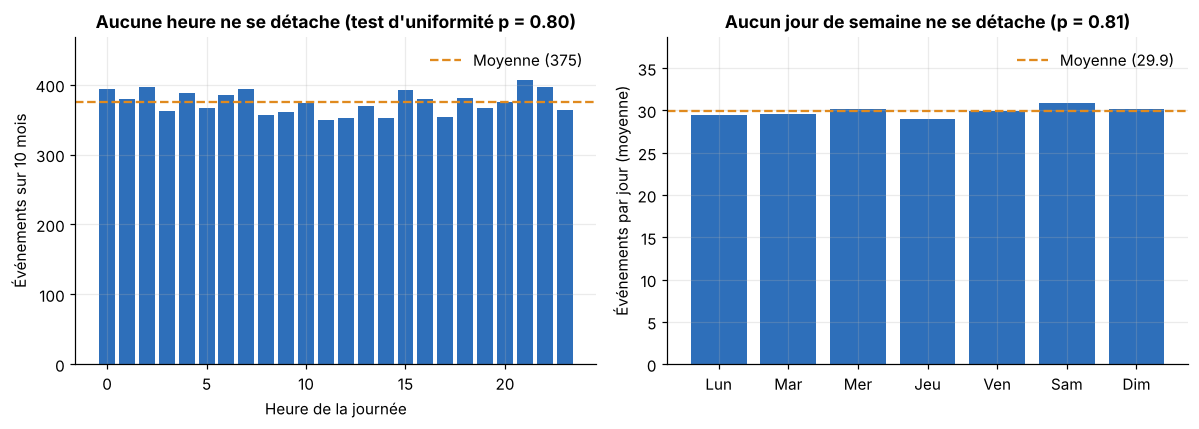

In [7]:
heure = q("SELECT hour_key AS heure, COUNT(*) AS n FROM fact_container_event GROUP BY 1 ORDER BY 1")
jour["jour_sem"] = jour.full_date.dt.dayofweek
sem = jour.groupby("jour_sem").nb_evenements.mean()
p_h = stats.chisquare(heure.n).pvalue
p_s = stats.f_oneway(*[x.nb_evenements.values for _, x in jour.groupby("jour_sem")]).pvalue
noms = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.bar(heure.heure, heure.n, color=BLEU)
a1.axhline(heure.n.mean(), color=ORANGE, ls="--", label=f"Moyenne ({heure.n.mean():.0f})")
a1.set_title(f"Aucune heure ne se détache (test d'uniformité p = {p_h:.2f})")
a1.set_xlabel("Heure de la journée"); a1.set_ylabel("Événements sur 10 mois"); a1.set_ylim(0, heure.n.max() * 1.15); a1.legend(frameon=False)
a2.bar(noms, sem.values, color=BLEU)
a2.axhline(sem.mean(), color=ORANGE, ls="--", label=f"Moyenne ({sem.mean():.1f})")
a2.set_title(f"Aucun jour de semaine ne se détache (p = {p_s:.2f})")
a2.set_ylabel("Événements par jour (moyenne)"); a2.set_ylim(0, sem.max() * 1.25); a2.legend(frameon=False)
sauver("g2_heure_et_semaine")

**Interprétation.**
- Par heure, le volume varie de 350 (11 h) à 407 événements (21 h), soit environ **±8 %** autour de la moyenne de 375. Le test d'uniformité (p = 0,80) ne permet pas de conclure à une vraie différence : le « pic de 21 h » est compatible avec le hasard.
- Par jour de semaine, la moyenne va de 29,0 à 30,9 événements par jour (p = 0,81) : le terminal travaille **au même rythme tous les jours, week-end compris**.

**Décision possible.** Un terminal qui fonctionne 24 h sur 24 et 7 jours sur 7 a besoin d'une couverture **constante** (équipes en rotation), sans renfort ciblé sur une plage horaire. Si le comportement réel du terminal différait (par exemple des pics à l'arrivée des navires), il faudrait des horodatages issus d'un vrai système pour le voir : c'est une limite des données synthétiques.

## 4. KPI 2 : mouvements MOVE par zone de cour

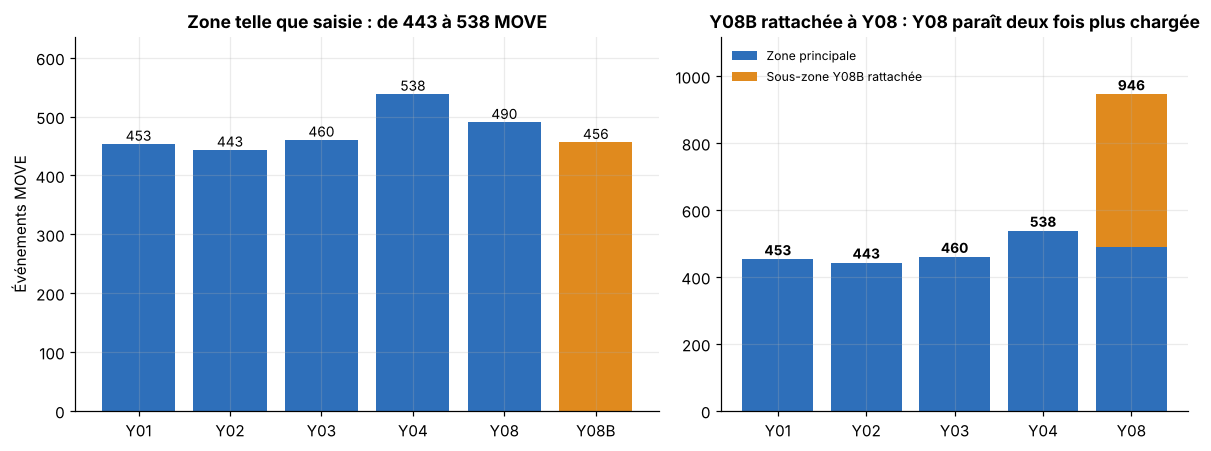

Test d'uniformité des 6 zones saisies : p = 0.021


In [8]:
zone = q("SELECT area_code, parent_area, nb_move FROM mart_kpi_move_by_area ORDER BY area_code")
base = zone[zone.area_code == zone.parent_area].set_index("parent_area").nb_move
total = zone.groupby("parent_area").nb_move.sum()
sous = (total - base.reindex(total.index)).fillna(0)
p_z = stats.chisquare(zone.nb_move).pvalue

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
a1.bar(zone.area_code, zone.nb_move, color=[ORANGE if c == "Y08B" else BLEU for c in zone.area_code])
for i, v in enumerate(zone.nb_move):
    a1.text(i, v + 6, str(v), ha="center", fontsize=9)
a1.set_title(f"Zone telle que saisie : de {zone.nb_move.min()} à {zone.nb_move.max()} MOVE")
a1.set_ylabel("Événements MOVE"); a1.set_ylim(0, zone.nb_move.max() * 1.18)
a2.bar(total.index, base.reindex(total.index), color=BLEU, label="Zone principale")
a2.bar(total.index, sous, bottom=base.reindex(total.index), color=ORANGE, label="Sous-zone Y08B rattachée")
for i, v in enumerate(total.values):
    a2.text(i, v + 12, str(v), ha="center", fontsize=9, fontweight="bold")
a2.set_title("Y08B rattachée à Y08 : Y08 paraît deux fois plus chargée")
a2.set_ylim(0, total.max() * 1.18); a2.legend(frameon=False, fontsize=8, loc="upper left")
sauver("g3_move_par_zone")
print(f"Test d'uniformité des 6 zones saisies : p = {p_z:.3f}")

In [9]:
# Y04 comparée à la moyenne des cinq autres zones saisies
autres = zone[zone.area_code != "Y04"].nb_move.mean()
print(f"Y04 : {100 * (zone.set_index('area_code').nb_move['Y04'] / autres - 1):.1f} % au-dessus de la moyenne des autres zones")

Y04 : 16.9 % au-dessus de la moyenne des autres zones


**Interprétation.**
- Zone par zone (graphique de gauche), les mouvements MOVE se répartissent entre **443 et 538**. **Y04 est la plus chargée** (538), environ 17 % au-dessus de la moyenne des autres zones. C'est la seule différence légèrement significative de toute l'étude (p ≈ 0,02), à prendre avec prudence : en multipliant les tests, une valeur de cet ordre peut apparaître par hasard.
- Une fois **Y08B rattachée à Y08** (graphique de droite), Y08 atteint 946 MOVE et semble deux fois plus chargée. **C'est un effet de regroupement** : Y08 additionne deux sous-zones de taille comparable aux autres zones (490 et 456). Le choix de rattacher Y08B change donc la conclusion.

**Décision possible.** Ne pas conclure que Y08 est « saturée » sans connaître la surface des zones : il faudrait rapporter les mouvements à la capacité de chaque zone. En attendant, **Y04** est la zone à surveiller en priorité. Cette lecture dépend de notre hypothèse sur Y08B, à faire valider par le propriétaire métier.

## 5. KPI 3 : volumes par navire et par service

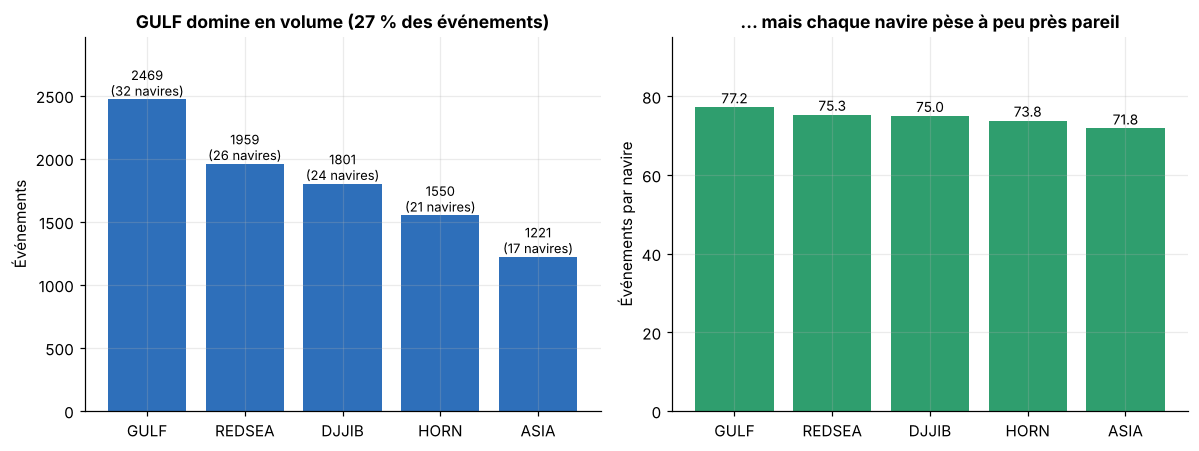

In [10]:
srv = q("SELECT * FROM mart_kpi_service ORDER BY nb_evenements DESC")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.bar(srv.service_code, srv.nb_evenements, color=BLEU)
for i, (n, nav) in enumerate(zip(srv.nb_evenements, srv.nb_navires)):
    a1.text(i, n + 30, f"{n}\n({nav} navires)", ha="center", fontsize=8.5)
a1.set_title(f"{srv.service_code.iloc[0]} domine en volume ({srv.pct_evenements.iloc[0]:.0f} % des événements)")
a1.set_ylabel("Événements"); a1.set_ylim(0, srv.nb_evenements.max() * 1.2)
a2.bar(srv.service_code, srv.evenements_par_navire, color=VERT)
for i, v in enumerate(srv.evenements_par_navire):
    a2.text(i, v + 1, f"{v:.1f}", ha="center", fontsize=9)
a2.set_title("... mais chaque navire pèse à peu près pareil")
a2.set_ylabel("Événements par navire"); a2.set_ylim(0, 95)
sauver("g4_volumes_par_service")

In [11]:
# Le volume par navire diffère-t-il d'un service à l'autre ? (ANOVA)
nav = q("SELECT service_code, nb_evenements FROM mart_kpi_vessel")
p_nav = stats.f_oneway(*[g.nb_evenements.values for _, g in nav.groupby("service_code")]).pvalue
print(f"ANOVA événements par navire selon le service : p = {p_nav:.2f}")

ANOVA événements par navire selon le service : p = 0.38


**Interprétation.**
- **GULF** génère le plus d'événements (2 469, soit 27,4 %), devant REDSEA (1 959), DJJIB (1 801), HORN (1 550) et ASIA (1 221).
- Cette hiérarchie s'explique **uniquement par le nombre de navires** de chaque service (32 pour GULF, 17 pour ASIA). Par navire, le volume est presque identique : de **71,8 à 77,2 événements** (différence non significative, p = 0,38).

**Décision possible.** Pour planifier les ressources, il faut anticiper le **nombre d'escales par service** plutôt que la taille de chaque escale : une escale GULF et une escale ASIA demandent à peu près le même travail. Le service GULF doit recevoir le plus de ressources parce qu'il a le plus d'escales, pas parce que ses escales sont plus lourdes.

## 6. KPI 4 : activité par client

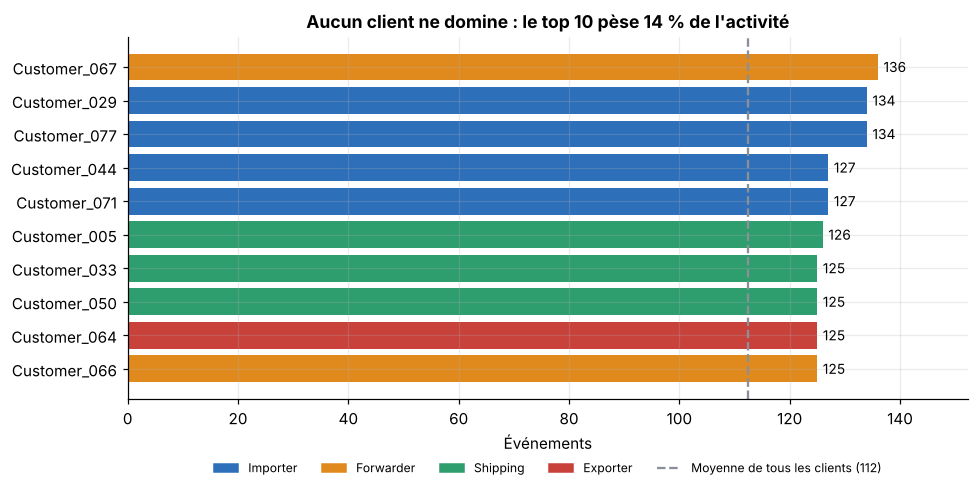

,nb_clients,evenements,moyenne_par_client
customer_type,,,
Exporter,16,1758,109.9
Forwarder,20,2255,112.8
Importer,29,3290,113.4
Shipping,15,1697,113.1


In [12]:
cli = q("SELECT customer_name, customer_type, nb_evenements FROM mart_kpi_customer ORDER BY nb_evenements DESC")
couleur_type = {"Importer": BLEU, "Forwarder": ORANGE, "Shipping": VERT, "Exporter": ROUGE}
top = cli.head(10).iloc[::-1]
pct_top10 = 100 * cli.nb_evenements.head(10).sum() / cli.nb_evenements.sum()

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(top.customer_name, top.nb_evenements, color=[couleur_type[t] for t in top.customer_type])
ax.axvline(cli.nb_evenements.mean(), color=GRIS, ls="--", label=f"Moyenne de tous les clients ({cli.nb_evenements.mean():.0f})")
for y, v in enumerate(top.nb_evenements):
    ax.text(v + 1, y, str(v), va="center", fontsize=9)
ax.set_title(f"Aucun client ne domine : le top 10 pèse {pct_top10:.0f} % de l'activité")
ax.set_xlabel("Événements"); ax.set_xlim(0, cli.nb_evenements.max() * 1.12)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in couleur_type.values()]
ax.legend(handles + [ax.lines[0]], list(couleur_type) + [ax.lines[0].get_label()], frameon=False, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14))
sauver("g5_activite_par_client")
display(cli.groupby("customer_type").nb_evenements.agg(nb_clients="count", evenements="sum", moyenne_par_client="mean").round(1))

In [13]:
# L'activité moyenne d'un client dépend-elle de son type ? (ANOVA)
tc = q("SELECT customer_type, nb_evenements FROM mart_kpi_customer")
p_cli = stats.f_oneway(*[g.nb_evenements.values for _, g in tc.groupby("customer_type")]).pvalue
print(f"ANOVA activité par client selon le type : p = {p_cli:.2f}")

ANOVA activité par client selon le type : p = 0.66


**Interprétation.**
- Les clients vont de **91 à 136 événements** pour une moyenne de 112,5. Le premier client (Customer_067) ne représente que **1,5 %** de l'activité, et les 10 premiers **14,3 %** : la clientèle est très dispersée, aucun client ne pèse assez pour mettre le terminal en dépendance.
- Par type, les moyennes sont proches (Exporter 109,9 ; Forwarder 112,8 ; Importer 113,4 ; Shipping 113,1) et les écarts ne sont pas significatifs (p = 0,66). Les importateurs pèsent le plus au total (3 290 événements) simplement parce qu'ils sont les plus nombreux (29 clients).

**Décision possible.** Le risque commercial lié à la concentration est faible. En revanche, on ne peut pas dégager un « client stratégique » avec ces données : un classement par chiffre d'affaires ou par durée de séjour serait nécessaire pour cela.

## 7. KPI 5 : poids moyen par type d'événement

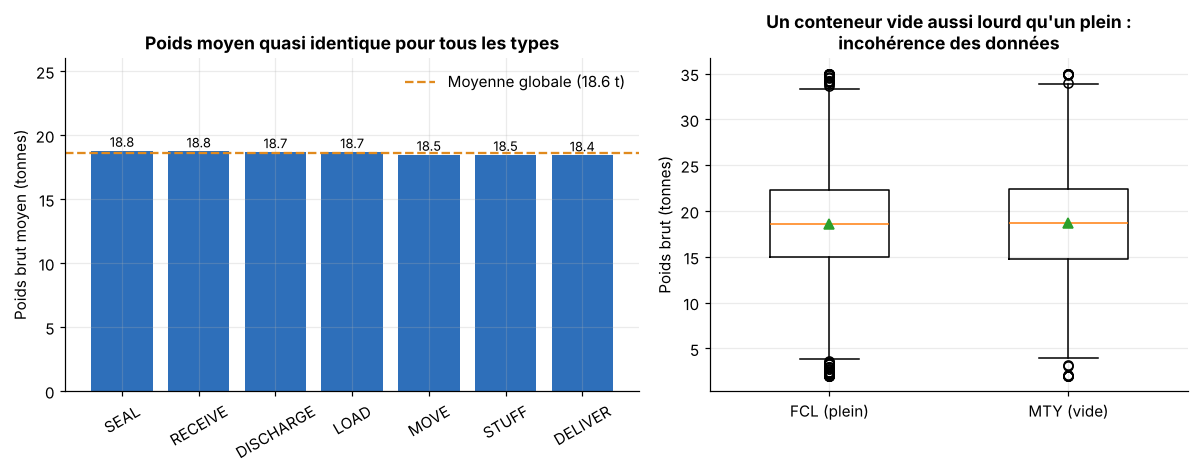

Médiane FCL : 18542 kg | Médiane MTY : 18640 kg
Test FCL vs MTY (Mann-Whitney) : p = 0.784


In [14]:
typ = q("SELECT event_type, poids_moyen_kg FROM mart_kpi_event_type ORDER BY poids_moyen_kg DESC")
poids = q("SELECT fs.freight_status AS statut, f.gross_weight_kg AS poids FROM fact_container_event f JOIN dim_freight_status fs ON fs.freight_key = f.freight_key")
moy_globale = poids.poids.mean() / 1000

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
a1.bar(typ.event_type, typ.poids_moyen_kg / 1000, color=BLEU)
a1.axhline(moy_globale, color=ORANGE, ls="--", label=f"Moyenne globale ({moy_globale:.1f} t)")
for i, v in enumerate(typ.poids_moyen_kg / 1000):
    a1.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=8.5)
a1.set_title("Poids moyen quasi identique pour tous les types")
a1.set_ylabel("Poids brut moyen (tonnes)"); a1.set_ylim(0, 26); a1.legend(frameon=False, loc="upper right")
a1.tick_params(axis="x", labelrotation=30)
a2.boxplot([poids[poids.statut == s].poids / 1000 for s in ["FCL", "MTY"]], widths=0.5, showmeans=True)
a2.set_xticks([1, 2]); a2.set_xticklabels(["FCL (plein)", "MTY (vide)"])
a2.set_title("Un conteneur vide aussi lourd qu'un plein :\nincohérence des données")
a2.set_ylabel("Poids brut (tonnes)")
sauver("g6_poids")
print("Médiane FCL :", round(poids[poids.statut == "FCL"].poids.median()), "kg | Médiane MTY :", round(poids[poids.statut == "MTY"].poids.median()), "kg")
print("Test FCL vs MTY (Mann-Whitney) : p =", round(stats.mannwhitneyu(poids[poids.statut == "FCL"].poids, poids[poids.statut == "MTY"].poids).pvalue, 3))

In [15]:
# Le poids moyen dépend-il du type d'événement ? (ANOVA)
pt = q("SELECT t.event_type, f.gross_weight_kg AS poids FROM fact_container_event f JOIN dim_event_type t ON t.event_type_key = f.event_type_key")
p_poids = stats.f_oneway(*[g.poids.values for _, g in pt.groupby("event_type")]).pvalue
print(f"ANOVA poids selon le type d'événement : p = {p_poids:.2f}")

ANOVA poids selon le type d'événement : p = 0.58


**Interprétation.**
- Le poids brut moyen est de **18,6 tonnes**, et il varie très peu selon le type d'événement (de 18,4 t pour DELIVER à 18,8 t pour SEAL, p = 0,58). Un déplacement en cour ou un chargement sur navire concerne donc des conteneurs de même poids moyen.
- **Anomalie à signaler :** les conteneurs **vides (MTY)** ont exactement la même distribution de poids que les pleins (médianes de 18,5 t pour les pleins et 18,6 t pour les vides, p = 0,78, et des valeurs jusqu'à 35 t). Or un conteneur vide pèse en réalité quelques tonnes. Le poids semble donc généré **indépendamment du statut**.

**Décision possible.** Ne pas utiliser le poids pour estimer la charge réelle manutentionnée tant que cette incohérence n'est pas levée. En production, on ajouterait une règle de qualité (poids d'un conteneur MTY borné à sa tare) et on interrogerait la source.

## 8. KPI 6 : part de conteneurs pleins (FCL) et vides (MTY)

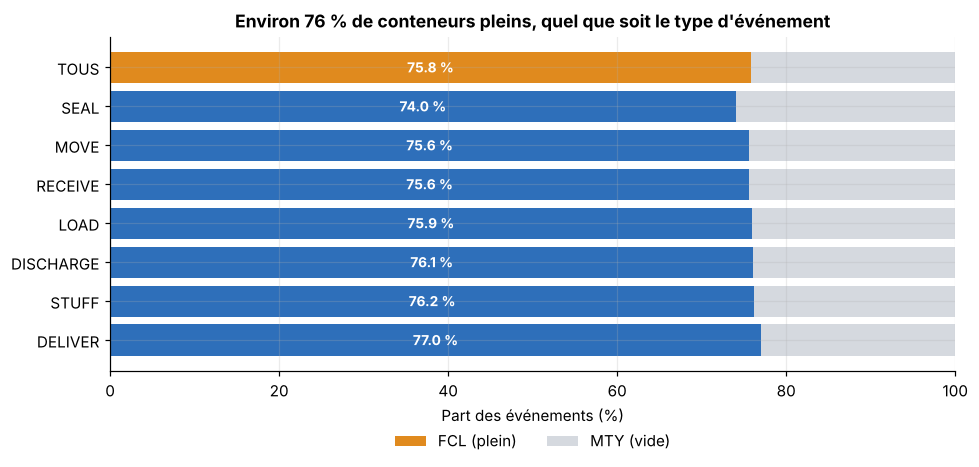

In [16]:
fcl = q("SELECT event_type, pct_fcl FROM mart_kpi_event_type ORDER BY pct_fcl")
glob = q("SELECT pct_evenements FROM mart_kpi_freight WHERE freight_status = 'FCL'").iloc[0, 0]
lignes = pd.concat([pd.DataFrame({"event_type": ["TOUS"], "pct_fcl": [glob]}), fcl], ignore_index=True)

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(lignes.event_type, lignes.pct_fcl, color=[ORANGE if t == "TOUS" else BLEU for t in lignes.event_type], label="FCL (plein)")
ax.barh(lignes.event_type, 100 - lignes.pct_fcl, left=lignes.pct_fcl, color="#D5D9DF", label="MTY (vide)")
for y, v in enumerate(lignes.pct_fcl):
    ax.text(v / 2, y, f"{v:.1f} %", va="center", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_title(f"Environ {glob:.0f} % de conteneurs pleins, quel que soit le type d'événement")
ax.set_xlabel("Part des événements (%)"); ax.set_xlim(0, 100); ax.invert_yaxis()
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.14))
sauver("g7_part_fcl_mty")

**Interprétation.**
- **75,8 %** des événements concernent des conteneurs pleins (FCL) et **24,2 %** des vides (MTY), soit à peu près **3 pleins pour 1 vide**. La part reste comprise entre 74,0 % (SEAL) et 77,0 % (DELIVER) selon le type d'événement.
- Cette stabilité est surprenante : dans un vrai terminal, certaines opérations (par exemple le repositionnement de vides) concernent surtout des MTY. Ici, la répartition semble indépendante du type d'opération.

**Décision possible.** Environ un quart des mouvements porte sur des conteneurs vides : c'est un volume non négligeable à optimiser (regroupement, repositionnement) puisqu'il ne génère pas de marchandise. Une analyse par client ou par service permettrait de repérer où les vides s'accumulent.

## 9. Synthèse des six indicateurs

In [17]:
recap = pd.DataFrame([
    ("Événements par jour",        "Moyenne",                   f"{moy:.1f} (min {jour.nb_evenements.min()}, max {jour.nb_evenements.max()})"),
    ("MOVE par zone Yard",         "Zone la plus chargée",      f"{zone.sort_values('nb_move').iloc[-1].area_code} : {zone.nb_move.max()} MOVE"),
    ("Volumes par service",        "Service le plus actif",     f"{srv.service_code.iloc[0]} : {srv.nb_evenements.iloc[0]} événements ({srv.pct_evenements.iloc[0]:.1f} %)"),
    ("Activité par client",        "Part du top 10",            f"{pct_top10:.1f} % de l'activité"),
    ("Poids moyen par événement",  "Moyenne globale",           f"{moy_globale:.1f} tonnes"),
    ("Part FCL / MTY",             "Part de conteneurs pleins", f"{glob:.1f} % FCL / {100 - glob:.1f} % MTY"),
], columns=["KPI", "Indicateur", "Valeur"])
recap

,KPI,Indicateur,Valeur
0,Événements par jour,Moyenne,"29.9 (min 14, max 50)"
1,MOVE par zone Yard,Zone la plus chargée,Y04 : 538 MOVE
2,Volumes par service,Service le plus actif,GULF : 2469 événements (27.4 %)
3,Activité par client,Part du top 10,14.3 % de l'activité
4,Poids moyen par événement,Moyenne globale,18.6 tonnes
5,Part FCL / MTY,Part de conteneurs pleins,75.8 % FCL / 24.2 % MTY


## 10. Conclusions
### Ce que montrent les données
1. **Activité régulière :** 29,9 événements par jour (14 à 50), sans différence significative entre mois, heures ou jours de la semaine.
2. **Jours chargés :** 7 des 9 tombent entre le 1er mai et le 10 juillet. C'est une **piste**, pas une preuve : la période a été choisie après observation.
3. **Cour :** Y04 est la première zone saisie (538 MOVE). Le rattachement de Y08B change le classement (Y08 : 946).
4. **Services :** GULF domine par son **nombre de navires**, pas par la taille de ses escales.
5. **Clients :** activité dispersée (10 premiers : 14,3 %).
6. **Qualité métier :** le poids des conteneurs vides est distribué comme celui des pleins, ce qui est physiquement incohérent.

### Décisions possibles
| Constat | Décision proposée | À vérifier avant |
|---|---|---|
| Flux régulier | équipes pour environ 30 événements par jour, marge jusqu'à 50 | horodatages réels |
| Y04 en tête | la surveiller | capacité de chaque zone |
| Effet du nombre de navires | planifier selon les escales par service | planning des escales |
| Poids MTY incohérent | corriger à la source, ajouter une règle sur la tare | source du poids |

### Limites
Données synthétiques et très homogènes, une seule période de 10 mois, aucune mesure de capacité, de chiffre d'affaires ni de durée de séjour. Les résultats décrivent ce jeu de données et ne se généralisent pas à un terminal réel.

In [18]:
con.close()